In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

In [9]:
# Basic quantities, loading and converting to coordinates on Galactic plane

R0 = 8.15

# Assuming df_2 contains:
# l_deg, b_deg, distance_kpc

#df_2 = pd.read_csv('./Mopra/13CO/Mopra_Full_Cloud_Catalogue_cleaned.csv')
#df_2 = pd.read_csv('Full_test_catalogue.csv')
df_2 = pd.read_csv('../FUGIN_data/13CO/Inner_FUGIN_Mass_catalogue_complete.csv')


#mask = df_2['M_13CO_X_Sol'] > 10 ** 5
#mask= df_2['M_13CO_X_Sol'] > 10 ** 4
#mask = (df_2['M_13CO_X_Sol'] / df_2['final_distance'] ** 2) > 75.7
mask = df_2['M_pixel_Sol_13'] > 10 ** 4

df_2 = df_2[mask]

l = np.radians(df_2["x_cen"].to_numpy())
b = np.radians(df_2["y_cen"].to_numpy())
d = df_2["final_distance"].to_numpy()

X = d * np.cos(b) * np.sin(l)
Y = R0 - d * np.cos(b) * np.cos(l)

R = np.hypot(X, Y)

# Reid azimuth convention
beta = np.degrees(np.arctan2(X, Y))

df_2["X_kpc"] = X
df_2["Y_kpc"] = Y
df_2["R_kpc"] = R
df_2["beta_deg"] = beta
df_2["ln_R"] = np.log(R)

In [10]:
# Old function from Mopra_spiral_arms_Reid.py

def reid_arm(name, n=2000, extend_low=0, extend_high=0,
             params=None):

    if params is None:
        params = parameters

    bmin, bmax, bkink, Rkink, p_low, p_high = params[name]

    beta = np.linspace(
        bmin - extend_low,
        bmax + extend_high,
        n
    )

    pitch = np.where(beta <= bkink, p_low, p_high)

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    original = (beta >= bmin) & (beta <= bmax)

    return {
        "beta": beta,
        "R": R,
        "X": X,
        "Y": Y,
        "original": original
    }

parameters = {
    "3-kpc":   (15, 18, 15, 3.52, -4.2, -4.2),
    "Norma":   (5, 54, 18, 4.46, -1.0, 19.5),
    "Sct-Cen": (0, 104, 23, 4.91, 14.1, 12.1),
    "Sgr-Car": (2, 97, 24, 6.04, 17.1, 1.0),
    "Local":   (-8, 34, 9, 8.26, 11.4, 11.4),
    "Perseus": (-23, 115, 40, 8.87, 10.3, 8.7),
    "Outer":   (-16, 71, 18, 12.24, 3.0, 9.4),
}

# Fill these with verified Reid (2019) width values, in kpc
arm_widths = {
    "Norma": 0.14,
    "Sct-Cen" : 0.23,
    "Sgr-Car" : 0.27,
    "Perseus" : 0.35,
    "3-kpc"   : 0.18
}

In [11]:
# Assigning clouds to arms using KD Tree

arm_names = ["Norma", "Sct-Cen", "Sgr-Car", "Perseus", "3-kpc"]

colours = {
    "Norma": "red",
    "Sct-Cen": "blue",
    "Sgr-Car": "purple",
    "Perseus": "black",
    "3-kpc": "orange"
}

# Generate all four arms
extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 130,
        extend_high =130
    )
    for name in arm_names
}

# Catalogue coordinates
cloud_xy = df_2[["X_kpc", "Y_kpc"]].to_numpy(dtype=float)  # Collect the coordinates of each cloud on the (X,Y) Galactic plane
valid = np.isfinite(cloud_xy).all(axis=1)

# Calculate distances to each arm
for name, arm in extended_arms.items():

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])  # Collect the points making up each arm on the Galactic plane

    tree = cKDTree(arm_xy)  # Create the KD tree

    distances = np.full(len(df_2), np.nan)

    distances[valid], _ = tree.query(cloud_xy[valid]) 
    # distances: the distance, in kpc, from each cloud to the nearest sampled point on that arm.
    # indices: the index of that nearest arm point within arm_xy.

    df_2[f"dist_{name}_kpc"] = distances

# Identify nearest arm
distance_columns = [
    f"dist_{name}_kpc" for name in arm_names
]

distance_matrix = df_2[distance_columns].to_numpy()

closest_index = np.full(len(df_2), -1, dtype=int)
closest_distance = np.full(len(df_2), np.nan)

closest_index[valid] = np.argmin(
    distance_matrix[valid], axis=1  # Find arm with lowest distance
)                                  

closest_distance[valid] = np.min(
    distance_matrix[valid], axis=1
)

df_2["nearest_arm"] = [
    arm_names[i] if i >= 0 else None
    for i in closest_index
]

df_2["arm_distance_kpc"] = closest_distance

# Apply an initial association threshold
# Clouds will not be associated if their distance is higher than this, 3 * width
n_sigma = 3.0

df_2["assigned_arm"] = "Unassigned"

for name in arm_names:

    mask = (
        (df_2["nearest_arm"] == name)
        & (df_2["arm_distance_kpc"] <= n_sigma * arm_widths[name])
    )

    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

assigned_arm
Sgr-Car       123
Sct-Cen        97
3-kpc          37
Norma          37
Perseus        35
Unassigned     17
Name: count, dtype: int64


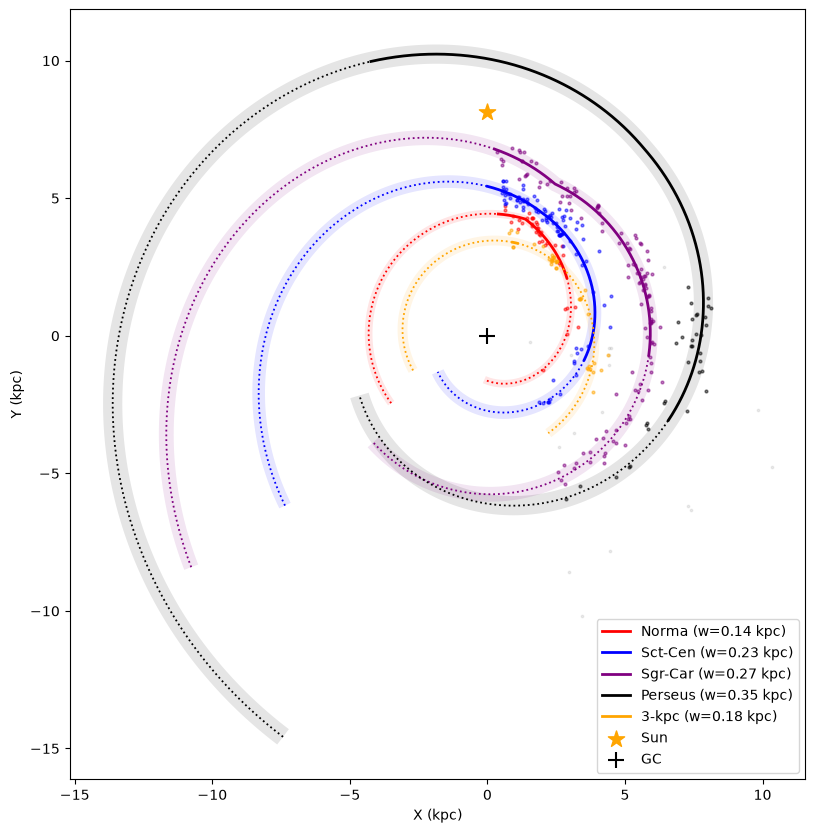

In [12]:
# Plot arms assignment ver.1

fig, ax = plt.subplots(figsize=(10, 10))

for name, arm in extended_arms.items():

    beta = arm["beta"]
    X = arm["X"]
    Y = arm["Y"]

    bmin, bmax, *_ = parameters[name]

    original = (beta >= bmin) & (beta <= bmax)
    extension_low = beta < bmin
    extension_high = beta > bmax

    # Arm width (kpc)
    w = arm_widths[name]

    # Tangent vector along the spiral
    dx = np.gradient(X)
    dy = np.gradient(Y)

    length = np.hypot(dx, dy)

    # Unit normal vector
    nx = -dy / length
    ny = dx / length

    # Boundaries at +/- one arm width
    X_upper = X + w * nx
    Y_upper = Y + w * ny

    X_lower = X - w * nx
    Y_lower = Y - w * ny

    # Fill the band between the two boundaries
    band_x = np.concatenate([X_upper, X_lower[::-1]])
    band_y = np.concatenate([Y_upper, Y_lower[::-1]])

    ax.fill(
        band_x,
        band_y,
        color=colours[name],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Original arm centreline
    ax.plot(
        X[original],
        Y[original],
        color=colours[name],
        lw=2,
        ls="-",
        label=f"{name} (w={w:.2f} kpc)",
        zorder=3
    )

    # Plot extensions separately to avoid artificial connections
    for mask in [extension_low, extension_high]:

        ax.plot(
            X[mask],
            Y[mask],
            color=colours[name],
            lw=1.3,
            ls=":",
            zorder=3
        )

# Catalogue clouds, coloured by assigned arm
for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.5,
        rasterized=True,
        zorder=4
    )

# Unassigned clouds
unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic Centre
ax.scatter(0, R0, marker="*", s=150,
           color="orange", zorder=5, label="Sun")

ax.scatter(0, 0, marker="+", s=120,
           color="black", zorder=5, label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()

plt.show()

In [13]:
## Add arm asssignments and distances to the dataframe

# Distances already calculated using KD-trees
distance_columns = [f"dist_{name}_kpc" for name in arm_names]

distance_matrix = df_2[distance_columns].to_numpy(dtype=float)

width_array = np.array([arm_widths[name] for name in arm_names])

# Normalize by arm width
normalized_distances = distance_matrix / width_array[None, :]

# Save normalized distances, called z
for j, name in enumerate(arm_names):
    df_2[f"z_{name}"] = normalized_distances[:, j]

In [14]:
# Check

valid = np.isfinite(normalized_distances).all(axis=1)

best_index = np.full(len(df_2), -1, dtype=int)
best_z = np.full(len(df_2), np.nan)

best_index[valid] = np.argmin(
    normalized_distances[valid],
    axis=1
)

best_z[valid] = np.min(
    normalized_distances[valid],
    axis=1
)

df_2["assigned_arm"] = "Unassigned"
df_2["arm_z"] = best_z

for j, name in enumerate(arm_names):
    mask = (best_index == j) & (best_z <= n_sigma)
    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

assigned_arm
Sgr-Car       124
Sct-Cen        99
3-kpc          39
Perseus        36
Norma          32
Unassigned     16
Name: count, dtype: int64


In [15]:
# Check

sorted_z = np.sort(normalized_distances, axis=1)

df_2["second_best_z"] = np.where(
    valid, sorted_z[:, 1], np.nan
)

df_2["arm_separation_z"] = (
    df_2["second_best_z"] - df_2["arm_z"]
)

print(
    df_2[
        ["Universal_ID", "assigned_arm",
         "arm_z", "second_best_z", "arm_separation_z"]
    ].head(10)
)
# Measure if 2 arms well approach a source. A large arm_separation means a good first choice.

    Universal_ID assigned_arm      arm_z  second_best_z  arm_separation_z
0              1   Unassigned  12.317722      18.386406          6.068684
1              2   Unassigned   7.524282      12.166083          4.641801
2              3   Unassigned   6.811894      11.848539          5.036644
3              4        3-kpc   0.898390       7.088126          6.189735
5              6      Sct-Cen   2.133326       2.150268          0.016942
12            13      Perseus   0.660884       2.203407          1.542523
15            16      Perseus   0.164984       2.922499          2.757515
18            19      Sgr-Car   0.214024       5.690423          5.476399
19            20      Sgr-Car   1.610877       3.904908          2.294030
20            21      Sct-Cen   1.404006       2.563408          1.159402


In [16]:
# Check

print(df_2["assigned_arm"].value_counts())

print(
    df_2.groupby("assigned_arm")["arm_z"]
    .agg(["count", "median", "mean"])
)

assigned_arm
Sgr-Car       124
Sct-Cen        99
3-kpc          39
Perseus        36
Norma          32
Unassigned     16
Name: count, dtype: int64
              count    median      mean
assigned_arm                           
3-kpc            39  0.764148  0.921324
Norma            32  0.893700  0.808016
Perseus          36  0.742371  0.945782
Sct-Cen          99  0.561543  0.851298
Sgr-Car         124  0.617488  0.794563
Unassigned       16  5.152602  5.933117


In [17]:
## Fit clouds to double Reid arm, with kink and 2 pitch angles

def fit_reid_arm(df, name, parameters, min_points=20):

    bmin, bmax, bkink, Rkink, p_low, p_high = parameters[name] # Looks like we are feeding Rkink, bkink into this and fit for R,b

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    # Azimuth relative to Reid kink, in radians
    beta = np.radians(subset["beta_deg"].to_numpy())
    beta_kink = np.radians(bkink)

    x = beta - beta_kink
    y = np.log(subset["R_kpc"].to_numpy())

    # Continuous piecewise-linear model, looks like with high and low we fit for under and over the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    A = np.column_stack([  ## A has the parameters for both high and low, before and after kink
        np.ones_like(x),
        x_low,
        x_high
    ])   

    # Ordinary least squares for the first experiment
    coefficients, residuals, rank, singular_values = (  ## Fitting for A containing high and low, coefficients are a, mhigh and mlow
        np.linalg.lstsq(A, y, rcond=None)
    )

    if rank < 3:
        return None

    a, m_low, m_high = coefficients

    return {
        "name": name,
        "N": len(subset),
        "Rkink_fit": np.exp(a),
        "pitch_low_fit": np.degrees(np.arctan(-m_low)),
        "pitch_high_fit": np.degrees(np.arctan(-m_high)),
        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }


fit_results = []

for name in arm_names:

    result = fit_reid_arm(df_2, name, parameters)

    if result is not None:
        fit_results.append(result)

fit_table = pd.DataFrame(fit_results)

print(fit_table.round(3).to_string(index=False))

   name   N  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma  32      4.465         -2.537          19.019        4.46            -1.0             19.5
Sct-Cen  99      4.971         10.197          13.163        4.91            14.1             12.1
Sgr-Car 124      6.019         14.187           0.789        6.04            17.1              1.0
  3-kpc  39      3.580         60.584          -3.798        3.52            -4.2             -4.2


In [18]:
## Load fit parameters

fitted_parameters = parameters.copy()

for result in fit_results:

    name = result["name"]

    bmin, bmax, bkink, _, _, _ = parameters[name]

    fitted_parameters[name] = (
        bmin,
        bmax,
        bkink,
        result["Rkink_fit"],
        result["pitch_low_fit"],
        result["pitch_high_fit"]
    )

In [21]:
# Create fitted arms

fitted_arms = {
    name: reid_arm(
        name,
        extend_low=30,
        extend_high=30,
        params=fitted_parameters
    )
    for name in arm_names
}

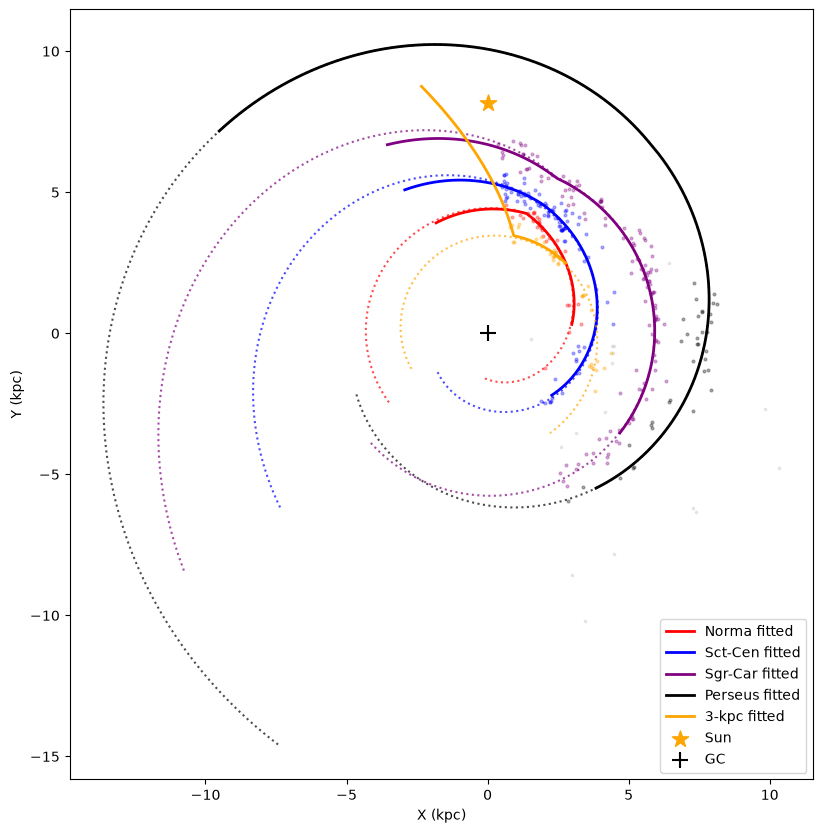

In [22]:
# Plot fitted arms

fig, ax = plt.subplots(figsize=(10, 10))

for name in arm_names:

    original = extended_arms[name]
    fitted = fitted_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7
    )

    # Newly fitted geometry
    ax.plot(
        fitted["X"],
        fitted["Y"],
        color=colours[name],
        ls="-",
        lw=2,
        label=f"{name} fitted"
    )

    # Clouds assigned to this arm
    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

ax.scatter(0, R0, marker="*", s=150, color="orange", label="Sun")
ax.scatter(0, 0, marker="+", s=120, color="black", label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()
plt.show()

In [23]:
# For Mopra or FGN alone everything above will have failed due to being exclusively on on side of the kink
# Try again with single segment, no kinks

def fit_single_segment(df, name, parameters, min_points=20):

    bmin, bmax, bkink, Rkink, p_low, p_high = parameters[name]

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if len(subset) < min_points:
        return None

    beta = subset["beta_deg"].to_numpy()
    R = subset["R_kpc"].to_numpy()

    # Check which side of the kink is sampled
    n_low = np.sum(beta <= bkink)
    n_high = np.sum(beta > bkink)

    if n_low > 0 and n_high > 0:
        print(f"{name}: clouds on both sides; skipping")
        return None

    side = "low" if n_low > 0 else "high"

    # Fit ln(R) = a + m * (beta - beta_kink)
    x = np.radians(beta - bkink)
    y = np.log(R)

    A = np.column_stack([np.ones_like(x), x])

    coefficients, _, rank, _ = np.linalg.lstsq(
        A, y, rcond=None
    )

    if rank < 2:
        return None

    a, m = coefficients

    return {
        "name": name,
        "N": len(subset),
        "side": side,
        "Rkink_fit": np.exp(a),
        "pitch_fit": np.degrees(np.arctan(-m)),
        "Rkink_Reid": Rkink,
        "pitch_Reid": p_low if side == "low" else p_high,
        "beta_span_deg": np.ptp(beta)
    }


fit_results = []

for name in arm_names:
    result = fit_single_segment(df_2, name, parameters)

    if result is not None:
        fit_results.append(result)

fit_table = pd.DataFrame(fit_results)

print(fit_table.round(3).to_string(index=False))

Norma: clouds on both sides; skipping
Sct-Cen: clouds on both sides; skipping
Sgr-Car: clouds on both sides; skipping
3-kpc: clouds on both sides; skipping
   name  N side  Rkink_fit  pitch_fit  Rkink_Reid  pitch_Reid  beta_span_deg
Perseus 36 high        8.6       8.28        8.87         8.7         77.967


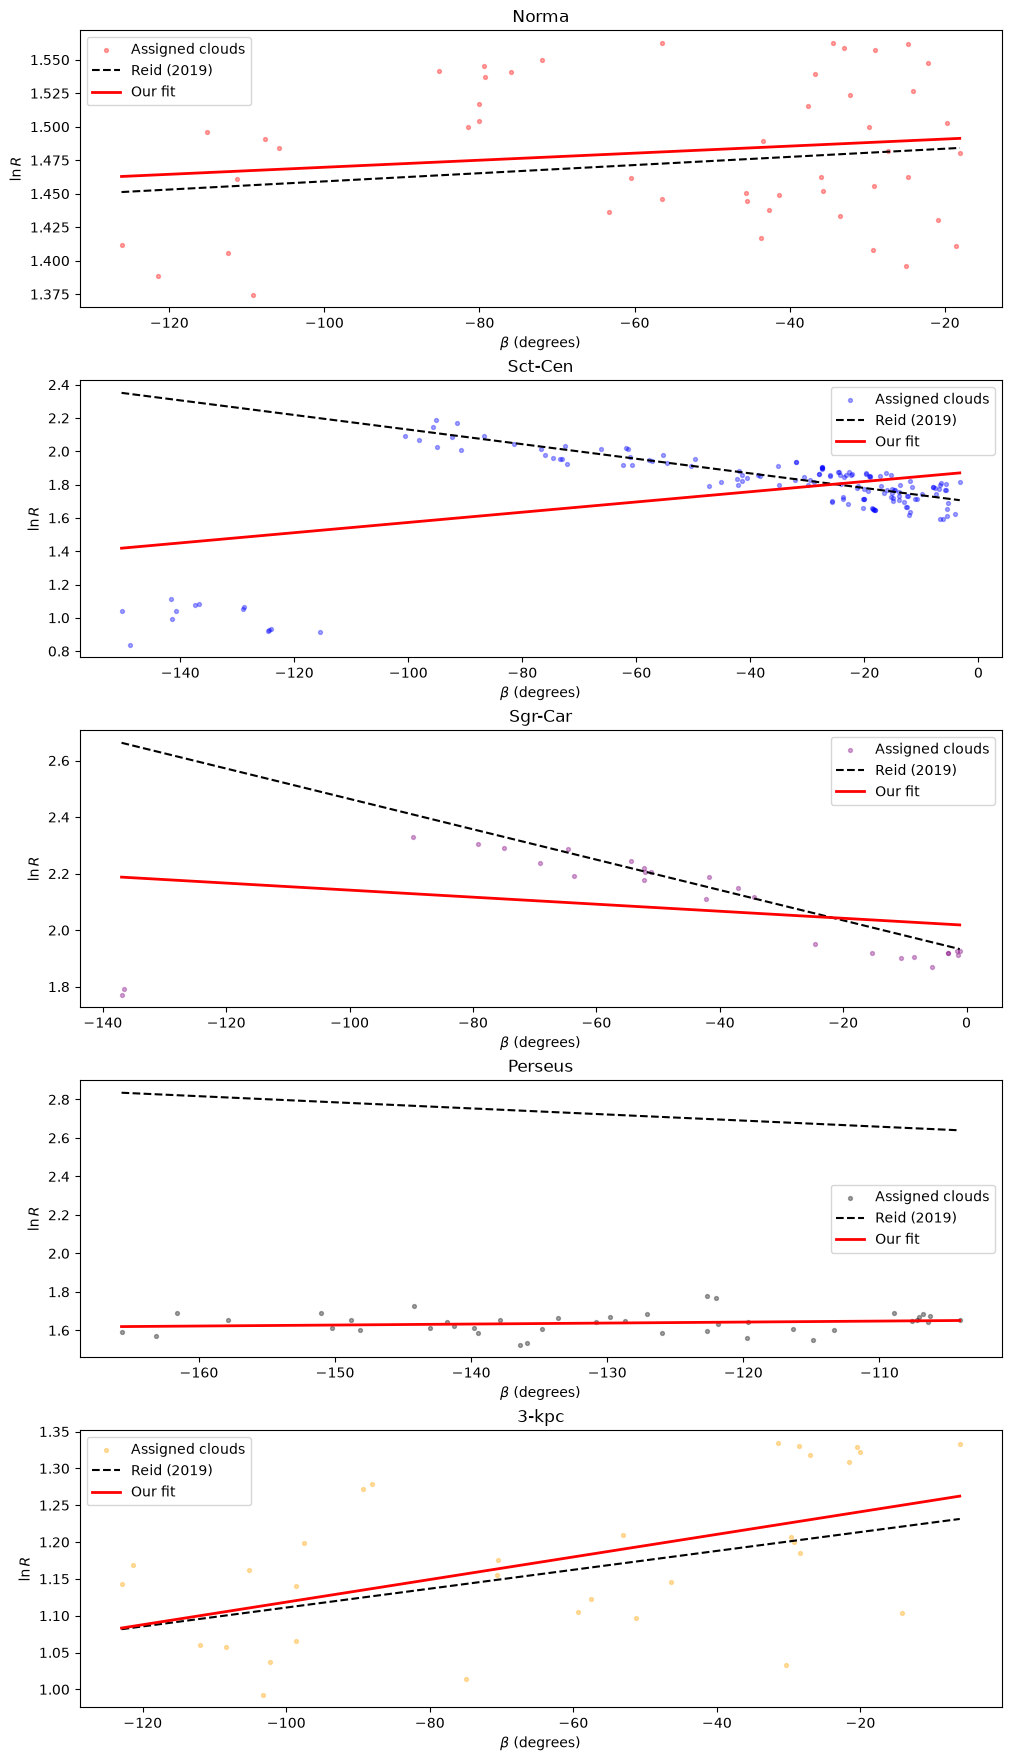

In [267]:
# Check fits of arms vs points

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True
)

for ax, name in zip(axes, arm_names):

    subset = df_2[df_2["assigned_arm"] == name]

    beta_cloud = subset["beta_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Fitted parameters
    result = next(
        (r for r in fit_results if r["name"] == name),
        None
    )

    if result is None:
        continue

    # Cover the observed azimuth interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    # Reid model on the sampled (low-beta) side
    lnR_reid = (
        np.log(Rkink)
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(p_low))
    )

    # Fitted model
    lnR_fit = (
        np.log(result["Rkink_fit"])
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(result["pitch_fit"]))
    )

    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    ax.plot(
        beta_grid,
        lnR_fit,
        color="red",
        lw=2,
        label="Our fit"
    )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()

In [269]:
# For Mopra the above plots show that outliers impact the fit negatively. 
# Try a different fit, Huber loss. Similar to least squares but less sensitive to outliers

def fit_robust_arm(df, name, parameters, min_points=20):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if len(subset) < min_points:
        return None

    beta = subset["beta_deg"].to_numpy()
    R = subset["R_kpc"].to_numpy()

    x = np.radians(beta - bkink)
    y = np.log(R)

    # Centre x near the observations to reduce
    # correlation between fitted intercept and slope
    x_ref = np.median(x)
    xc = x - x_ref

    # Initial ordinary least-squares solution
    A = np.column_stack([np.ones_like(xc), xc])
    a0, m0 = np.linalg.lstsq(A, y, rcond=None)[0]

    def residuals(theta):
        a, m = theta
        return y - (a + m * xc)

    result = least_squares(
        residuals,
        x0=[a0, m0],
        loss="huber",
        f_scale=0.03  # Arbitrary scale
    )

    a_fit, m_fit = result.x

    # Convert intercept back to Reid's kink azimuth
    ln_Rkink = a_fit - m_fit * x_ref

    return {
        "name": name,
        "N": len(subset),
        "Rkink_robust": np.exp(ln_Rkink),
        "pitch_robust": np.degrees(np.arctan(-m_fit)),
        "Rkink_Reid": Rkink,
        "pitch_Reid": p_low
    }

In [270]:
robust_results = []

for name in arm_names:
    result = fit_robust_arm(df_2, name, parameters)

    if result is not None:
        robust_results.append(result)

robust_table = pd.DataFrame(robust_results)

print(robust_table.round(3).to_string(index=False))

   name   N  Rkink_robust  pitch_robust  Rkink_Reid  pitch_Reid
  Norma  48         4.423        -0.287        4.46        -1.0
Sct-Cen 149         5.385         8.565        4.91        14.1
Sgr-Car  27         6.026        15.461        6.04        17.1
Perseus  41         5.801        -2.327        8.87        10.3
  3-kpc  32         3.734        -5.982        3.52        -4.2


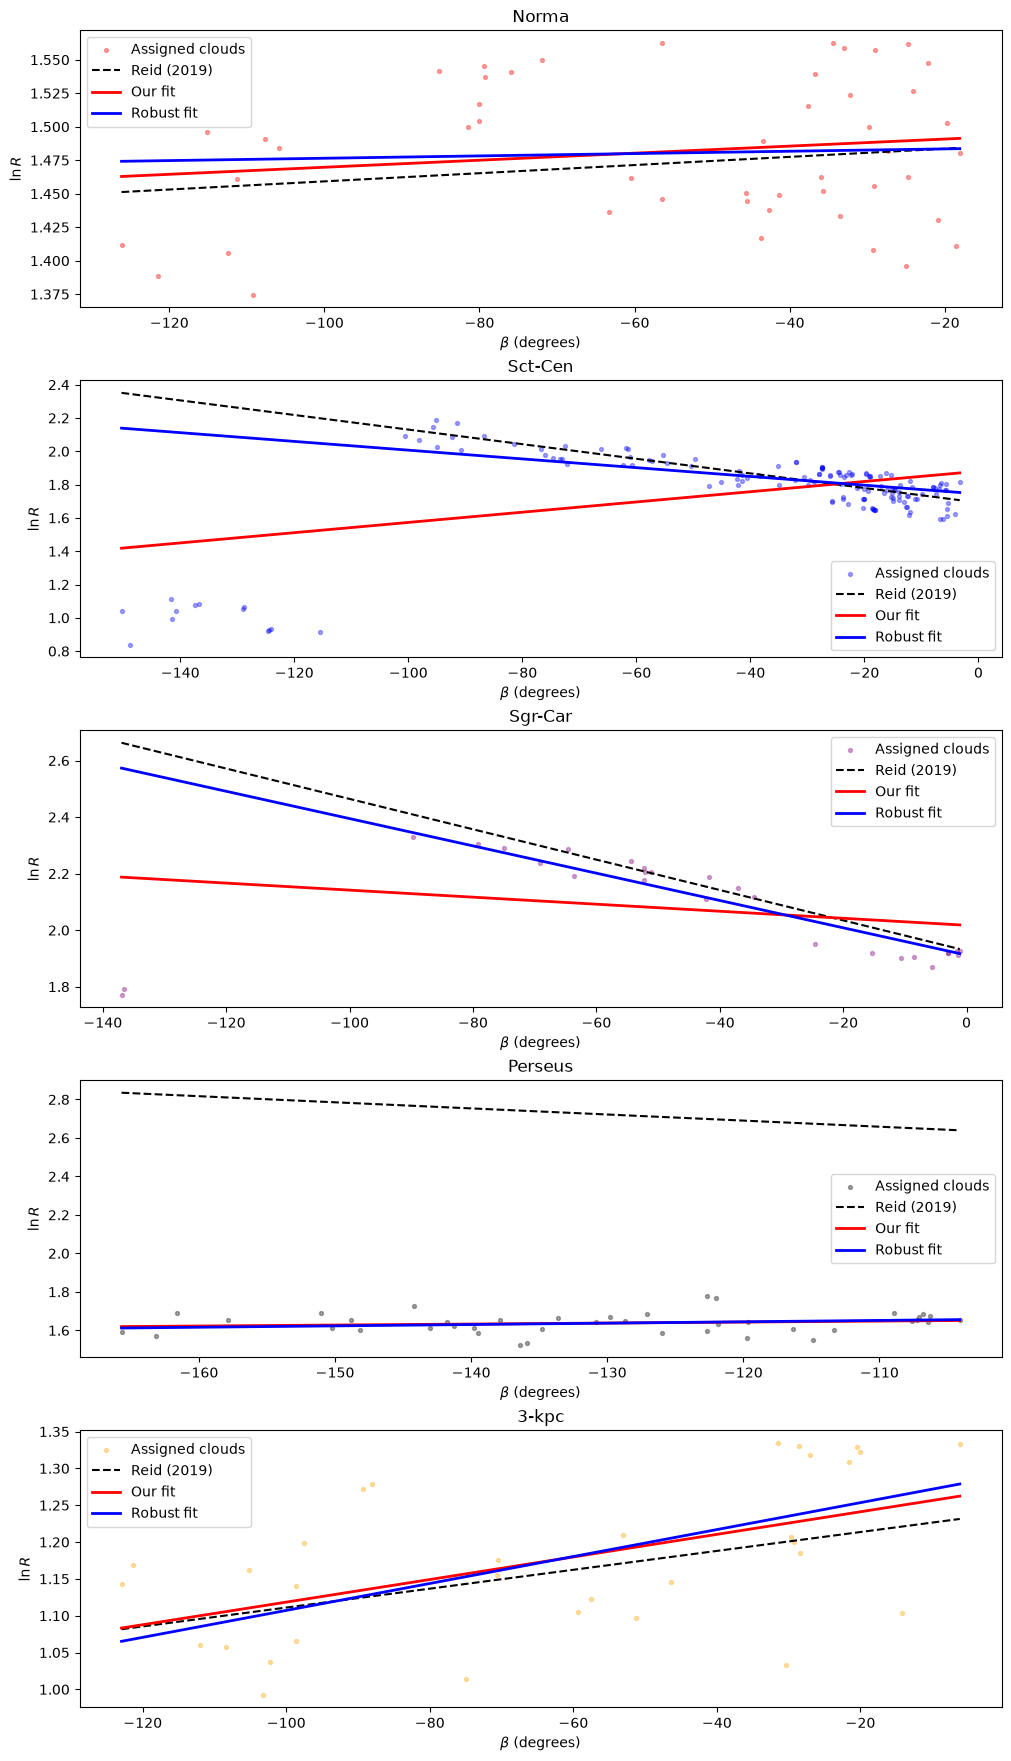

In [278]:
fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True
)

for ax, name in zip(axes, arm_names):

    subset = df_2[df_2["assigned_arm"] == name]

    beta_cloud = subset["beta_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Fitted parameters
    result = next(
        (r for r in fit_results if r["name"] == name),
        None
    )

    if result is None:
        continue

    # Fitted parameters
    result_robust = next(
        (r for r in robust_results if r["name"] == name),
        None
    )

    if result_robust is None:
        continue

    # Cover the observed azimuth interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    # Reid model on the sampled (low-beta) side
    lnR_reid = (
        np.log(Rkink)
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(p_low))
    )

    # Fitted model
    lnR_fit = (
        np.log(result["Rkink_fit"])
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(result["pitch_fit"]))
    )

    lnR_rob = (
        np.log(result_robust["Rkink_robust"])
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(result_robust["pitch_robust"]))
    )
    
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    ax.plot(
        beta_grid,
        lnR_fit,
        color="red",
        lw=2,
        label="Our fit"
    )

    ax.plot(
        beta_grid,
        lnR_rob,
        color="blue",
        lw=2,
        label="Robust fit"
    )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()

In [279]:
for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    bmin, bmax, *_ = parameters[name]

    beta = subset["beta_deg"].to_numpy()

    inside = (beta >= bmin) & (beta <= bmax)

    print(
        f"{name:10s} | "
        f"Total = {len(beta):4d} | "
        f"Within Reid interval = {inside.sum():4d} | "
        f"Outside = {(~inside).sum():4d} | "
        f"Beta range = [{beta.min():.1f}, {beta.max():.1f}]"
    )

Norma      | Total =   48 | Within Reid interval =    0 | Outside =   48 | Beta range = [-126.2, -18.1]
Sct-Cen    | Total =  149 | Within Reid interval =    0 | Outside =  149 | Beta range = [-150.3, -3.3]
Sgr-Car    | Total =   27 | Within Reid interval =    0 | Outside =   27 | Beta range = [-137.0, -1.1]
Perseus    | Total =   41 | Within Reid interval =    0 | Outside =   41 | Beta range = [-165.7, -104.1]
3-kpc      | Total =   32 | Within Reid interval =    0 | Outside =   32 | Beta range = [-123.0, -6.2]


In [280]:
df_2["arm_separation_z"]

8      1.593323
34     7.932187
36     6.926626
41     6.130246
42     7.512081
         ...   
977    3.301391
978    3.723519
979    5.752856
980    5.174854
981    4.257114
Name: arm_separation_z, Length: 407, dtype: float64